# Atomcamp Cohort 19 – CV Module: Transfer Learning & Fine-Tuning
**Assignment | Student: _Syed Yawar Ali Turab_**

**Project:** Accident AI Alert System | **Dataset:** Road Incident dataset (6 classes, Kaggle) | **Model:** EfficientNetB0 (Keras 3, PyTorch backend) | **Hardware:** NVIDIA RTX 3060 12 GB

### AI assistance declaration
> I used Claude to help me in development a good version of my code of Model and Finding Dataset. With this use Chatgpt and Gemini to write Readme Content.

## 0. Setup
This notebook is **fully self-contained**: it installs missing packages, **downloads the dataset automatically**, builds the train/val/test folders, then runs EDA, transfer learning, fine-tuning, evaluation and finally an **accident alert demo** built on the fine-tuned model.

**Backend:** Keras 3 running on the **PyTorch backend** (native CUDA on Windows; TensorFlow has no native Windows GPU support). TensorFlow is only used for loading images with `tf.data`.

In [3]:
import os, sys, subprocess, importlib.util
os.environ["KERAS_BACKEND"] = "torch" # set before keras is ever imported
for mod, pkg in [("numpy","numpy"),("pandas","pandas"),("matplotlib","matplotlib"),("seaborn","seaborn"), ("PIL","pillow"),("sklearn","scikit-learn"),("kagglehub","kagglehub"),("cv2","opencv-python"),("requests","requests"),("tensorflow","tensorflow"),("keras","keras")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

In [ ]:
import os, random, shutil, collections
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
os.environ["KERAS_BACKEND"] = "torch" # must be set BEFORE importing keras
import torch
import keras
from keras import layers
import tensorflow as tf # used ONLY for the tf.data image pipeline (kept on CPU)
tf.config.set_visible_devices([], "GPU")
import cv2
import time
from datetime import datetime


SEED = 42
random.seed(SEED); np.random.seed(SEED); keras.utils.set_random_seed(SEED)

print("Keras:", keras.__version__, "| backend:", keras.backend.backend(), "| torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available(), "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU")
if not torch.cuda.is_available():
    print("WARNING: torch cannot see the GPU. Run in a terminal:\n"
          "  pip uninstall -y torch torchvision\n"
          "  pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128")

# ---- configuration ----
IMG_SIZE, BATCH_SIZE = (224, 224), 32
AUTOTUNE = tf.data.AUTOTUNE
IMG_EXT = {".jpg", ".jpeg", ".png"}

Keras: 3.15.1 | backend: torch | torch: 2.15.0+cu132
CUDA available: True | NVIDIA GeForce RTX 3060


### Dataset download
Two public Kaggle datasets are downloaded with `kagglehub` (cached after the first run). They are combined into one 6-class dataset in Part 1.

In [5]:
def download_sources():
    import kagglehub
    traffic_net = Path(kagglehub.dataset_download("umairshahpirzada/traffic-net"))
    cctv = Path(kagglehub.dataset_download("ckay16/accident-detection-from-cctv-footage"))
    return traffic_net, cctv

TRAFFIC_NET_DIR, CCTV_DIR = download_sources()
SPLIT_DIR = Path("data/split_incidents")
print("Traffic-Net:", TRAFFIC_NET_DIR)
print("CCTV accident frames:", CCTV_DIR)

k:\Ali Turab Coding Space\Car_Accidents_and_deformation\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Traffic-Net: C:\Users\MinhalHnaqvi\.cache\kagglehub\datasets\umairshahpirzada\traffic-net\versions\1
CCTV accident frames: C:\Users\MinhalHnaqvi\.cache\kagglehub\datasets\ckay16\accident-detection-from-cctv-footage\versions\1


# Part 1 – Dataset Selection & Preparation

### Dataset justification
**What it is:** a **6-class road-incident dataset** that I assembled from two public Kaggle datasets of real photographs / video frames:

| Source | Classes used | Content |
|---|---|---|
| Traffic-Net (`umairshahpirzada/traffic-net`) | `accident`, `fire`, `dense_traffic`, `sparse_traffic` | ~4,400 real photographs of road scenes |
| Accident Detection from CCTV Footage (`ckay16/accident-detection-from-cctv-footage`) | `cctv_accident`, `cctv_normal` | frames extracted from real CCTV videos |

**Why I chose it:** I want to build an **accident AI alerting system for CCTV cameras**.
**accident or fire** while recognising dense traffic as *not* an accident, which should reduce false alarms. Related real-world problems: smart-city traffic monitoring, highway incident detection and emergency dispatch.

**Requirements check:** 6 classes, at least 200 images per class, real photographs / real video frames, and none of the excluded datasets.

### Folder structure & split strategy
All images from both sources are pooled (original train/test folders merged), then split **stratified** (class proportions preserved) into
**70% train / 15% val / 15% test** with a fixed seed. Files are copied into `data/split/{train,val,test}/<class>/`.
The test set is never used for training or model selection.

In [6]:
def label_traffic_net(f):
    name = f.parent.name.lower()
    for key, label in (("accident", "accident"), ("fire", "fire"), ("dense", "dense_traffic"), ("sparse", "sparse_traffic")):
        if key in name:
            return label

def label_cctv(f):
    name = f.parent.name.lower()
    if "non" in name:
        return "cctv_normal"
    if "accident" in name:
        return "cctv_accident"

def collect_images():
    rows = []
    for root, labeller, src in ((TRAFFIC_NET_DIR, label_traffic_net, "traffic_net"), (CCTV_DIR, label_cctv, "cctv")):
        for f in root.rglob("*"):
            if f.suffix.lower() in IMG_EXT and labeller(f):
                rows.append({"path": f, "label": labeller(f), "src": src})
    return pd.DataFrame(rows)

def make_splits(df, out_dir, seed=SEED):
    train, tmp = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=seed)
    val, test = train_test_split(tmp, test_size=0.50, stratify=tmp["label"], random_state=seed)
    parts = {"train": train, "val": val, "test": test}
    if not out_dir.exists():
        for split, part in parts.items():
            for idx, r in part.iterrows():
                dest = out_dir / split / r["label"]
                dest.mkdir(parents=True, exist_ok=True)
                shutil.copy2(r["path"], dest / f"{idx}_{r['path'].name}")
    return pd.concat([p.assign(split=s) for s, p in parts.items()], ignore_index=True)

df_all = collect_images()
counts = df_all["label"].value_counts()
assert df_all["label"].nunique() >= 5 and counts.min() >= 200 and len(df_all) >= 1000, "Dataset requirements not met"
print(df_all.groupby(["label", "src"]).size().unstack(fill_value=0))
print(f"Total images: {len(df_all)} | classes: {df_all['label'].nunique()} | min/class: {counts.min()}")

df = make_splits(df_all, SPLIT_DIR)
print(df.groupby(["split", "label"]).size().unstack(0))

src             cctv  traffic_net
label                            
accident           0         1100
cctv_accident    462            0
cctv_normal      527            0
dense_traffic      0         1100
fire               0         1100
sparse_traffic     0         1100
Total images: 5389 | classes: 6 | min/class: 462
split           test  train  val
label                           
accident         165    770  165
cctv_accident     70    323   69
cctv_normal       79    369   79
dense_traffic    165    770  165
fire             165    770  165
sparse_traffic   165    770  165


### Exploratory visualisation
A 5×5 grid of random training images with labels, followed by the class distribution per split.

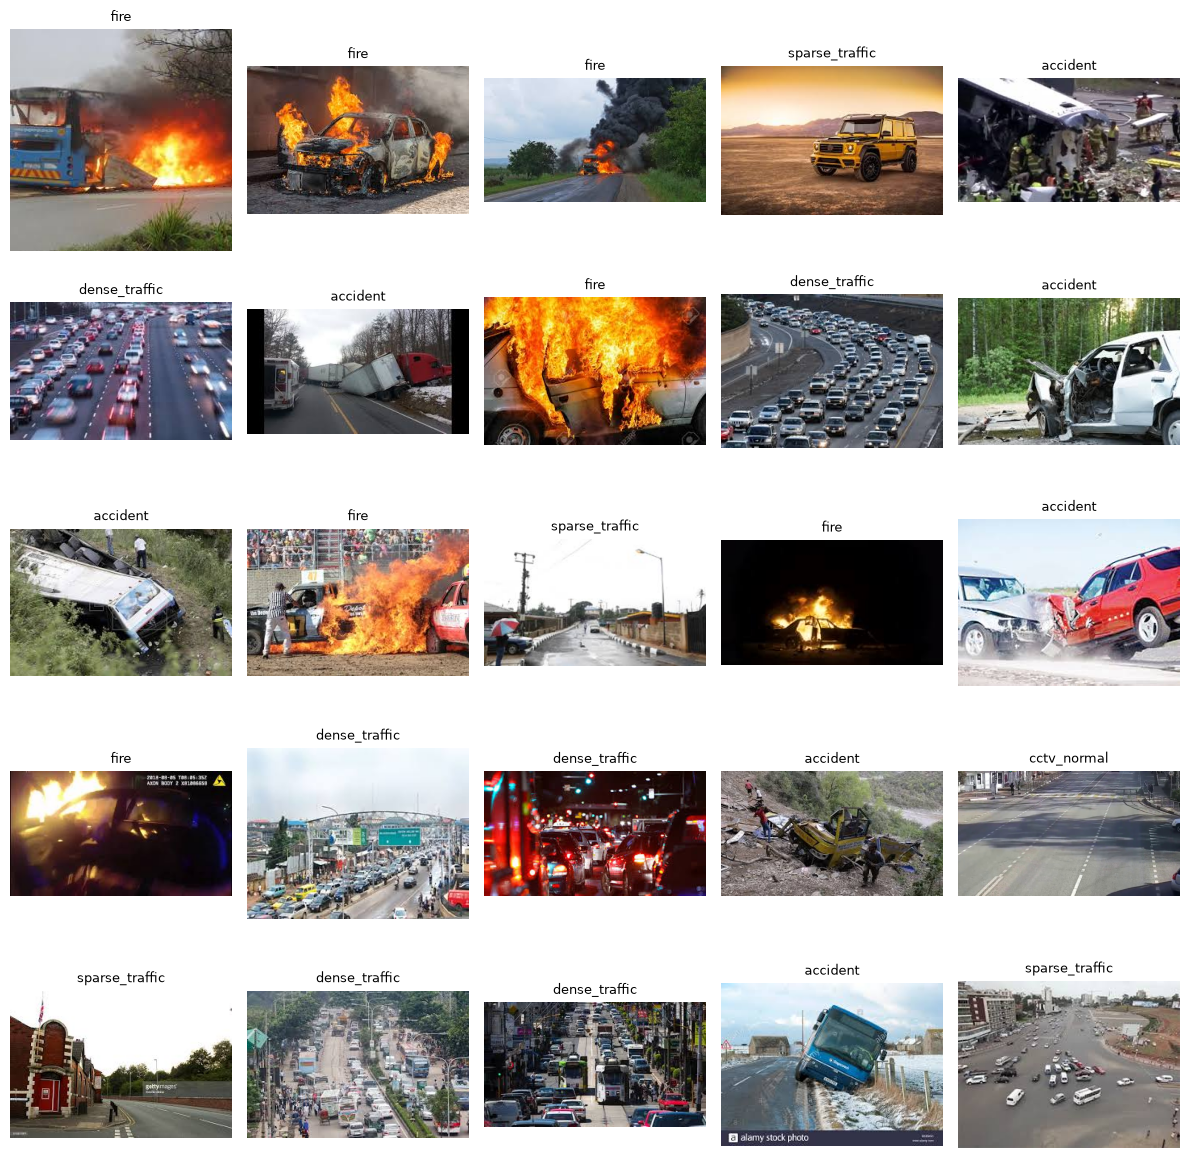

In [7]:
def show_grid(paths, titles, rows, cols, figsize=(12, 12)):
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax, p, t in zip(axes.ravel(), paths, titles):
        ax.imshow(Image.open(p).convert("RGB")); ax.set_title(t, fontsize=9); ax.axis("off")
    for ax in axes.ravel()[len(paths):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()

sample = df[df.split == "train"].sample(25, random_state=SEED)
show_grid(sample["path"], sample["label"], 5, 5)

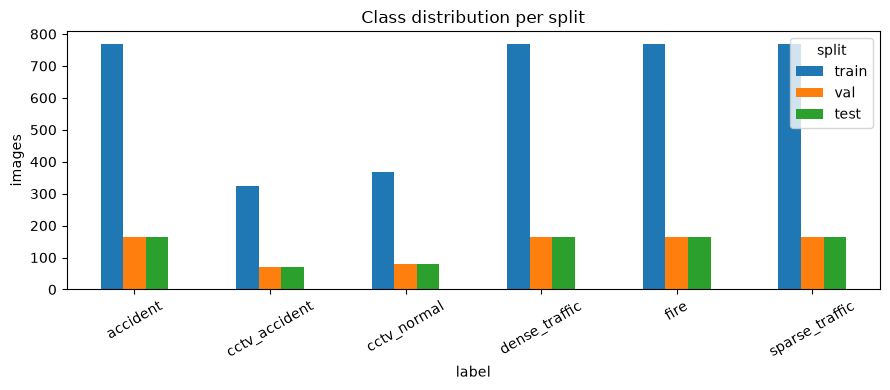

Imbalance ratio (largest/smallest class): 2.38


In [8]:
dist = df.groupby(["label", "split"]).size().unstack()[["train", "val", "test"]]
dist.plot(kind="bar", figsize=(9, 4)); plt.title("Class distribution per split"); plt.ylabel("images"); plt.xticks(rotation=30); plt.tight_layout(); plt.show()
ratio = counts.max() / counts.min()
print(f"Imbalance ratio (largest/smallest class): {ratio:.2f}")

In [9]:
sizes = [Image.open(p).size for p in df.sample(min(300, len(df)), random_state=SEED)["path"]]
sz = pd.DataFrame(sizes, columns=["width", "height"])
print(sz.describe().loc[["min", "mean", "max"]].round(0))

       width  height
min    168.0   118.0
mean   489.0   298.0
max   1280.0   720.0


### Data pipeline & augmentation
Datasets are loaded with `image_dataset_from_directory` (val/test **not shuffled** so predictions line up with file paths later).

**Augmentations** (built as Keras layers inside the model, so they run on the GPU and are only active during training):
| Augmentation | Why for this dataset |
|---|---|
| `RandomFlip("horizontal")` | A mirrored traffic scene or crash is still the same class. |
| `RandomRotation(0.1)` (±36°) | CCTV and phone cameras are rarely perfectly level. |
| `RandomZoom(0.15)` | Cameras differ in distance and field of view. |
| `RandomBrightness(0.2)` + `RandomContrast(0.2)` | Day, night, rain, glare and headlights change the lighting a lot. |

**Normalisation:** `keras.applications.EfficientNetB0` contains its own `Rescaling` + `Normalization` layers using the ImageNet mean/std,
so inputs must stay in the raw **0–255** range. I therefore do *not* divide by 255 myself.

Found 3772 files belonging to 6 classes.
Found 808 files belonging to 6 classes.
Found 809 files belonging to 6 classes.
['accident', 'cctv_accident', 'cctv_normal', 'dense_traffic', 'fire', 'sparse_traffic']


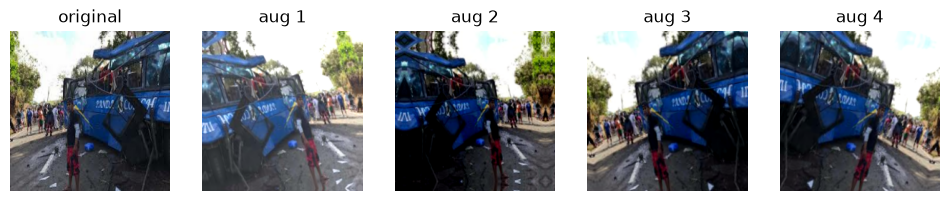

In [10]:
def load_split(split, shuffle):
    return keras.utils.image_dataset_from_directory(
        SPLIT_DIR / split, image_size=IMG_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED, label_mode="int")

train_raw, val_raw, test_raw = load_split("train", True), load_split("val", False), load_split("test", False)
class_names = train_raw.class_names
NUM_CLASSES = len(class_names)
train_ds, val_ds, test_ds = (d.prefetch(AUTOTUNE) for d in (train_raw, val_raw, test_raw))
print(class_names)

augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.2, value_range=(0, 255)),
    layers.RandomContrast(0.2),
], name="augmentation")

# Visualise augmentation on one image
imgs, _ = next(iter(train_raw))
plt.figure(figsize=(12, 3))
plt.subplot(1, 5, 1); plt.imshow(imgs[0].numpy().astype("uint8")); plt.title("original"); plt.axis("off")
for k in range(4):
    plt.subplot(1, 5, k + 2)
    plt.imshow(np.clip(keras.ops.convert_to_numpy(augmentation(imgs[:1].numpy(), training=True))[0], 0, 255).astype("uint8")); plt.title(f"aug {k+1}"); plt.axis("off")
plt.show()

# Transfer Learning (Frozen Base)

### Model choice & head
**Choice: EfficientNetB0.**~4M parameters (without top), far lighter than ResNet50 (~23M) or VGG16 (~14M conv + huge dense layers), while achieving
better ImageNet accuracy. With a few thousand training images, a small model is less prone to overfitting and trains fast on a 12 GB RTX 3060.

**Head:** `GlobalAveragePooling2D → Dropout(0.3) → Dense(256, ReLU) → Dropout(0.3) → Dense(num_classes, Softmax)`.
GAP replaces flatten (far fewer parameters, less overfitting); dropout regularises; the 256-unit Dense layer gives the head some capacity to remap ImageNet features to incident classes.
The base is called with `training=False` so its BatchNorm layers stay in inference mode.

In [11]:
def build_model(num_classes, dropout=0.3):
    base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,))
    base.trainable = False # freeze entire base
    inputs = keras.Input(shape=IMG_SIZE + (3,))
    x = augmentation(inputs)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="effnetb0_incident"), base

def param_counts(model):
    n = lambda ws: int(sum(np.prod(w.shape) for w in ws))
    return {"trainable": n(model.trainable_weights), "non_trainable": n(model.non_trainable_weights)}

model, base = build_model(NUM_CLASSES)
frozen_params = param_counts(model)
print("Frozen phase params:", frozen_params)
model.summary()

Frozen phase params: {'trainable': 329478, 'non_trainable': 4049571}


Model: "effnetb0_incident"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │         1,542 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,379,049 (16.70 MB)

 Trainable params: 329,478 (1.26 MB)

 Non-trainable params: 4,049,571 (15.45 MB)

### Training the frozen-base model
Adam (lr = 1e-3), sparse categorical cross-entropy, 10 epochs. The best-val-accuracy weights are checkpointed (no early stopping so we get the full 10-epoch curve).

k:\Ali Turab Coding Space\Car_Accidents_and_deformation\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 54s 450ms/step - accuracy: 0.7694 - loss: 0.6311 - val_accuracy: 0.8725 - val_loss: 0.3113
Epoch 2/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 54s 454ms/step - accuracy: 0.8454 - loss: 0.3921 - val_accuracy: 0.8886 - val_loss: 0.2668
Epoch 3/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 53s 452ms/step - accuracy: 0.8542 - loss: 0.3494 - val_accuracy: 0.8936 - val_loss: 0.2764
Epoch 4/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 52s 443ms/step - accuracy: 0.8704 - loss: 0.3403 - val_accuracy: 0.8849 - val_loss: 0.2640
Epoch 5/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 52s 442ms/step - accuracy: 0.8812 - loss: 0.3059 - val_accuracy: 0.8923 - val_loss: 0.2383
Epoch 6/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 53s 449ms/step - accuracy: 0.8894 - loss: 0.2727 - val_accuracy: 0.8973 - val_loss: 0.2247
Epoch 7/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 53s 451ms/step - accuracy: 0.8900 - loss: 0.2755 - val_accuracy: 0.9084 - val_loss: 0.2303
Epoch 8/10
118/118 ━━━━━━━━━━━━━━━━━━━━ 52s 439ms/step - accuracy: 0.8955 - loss: 0

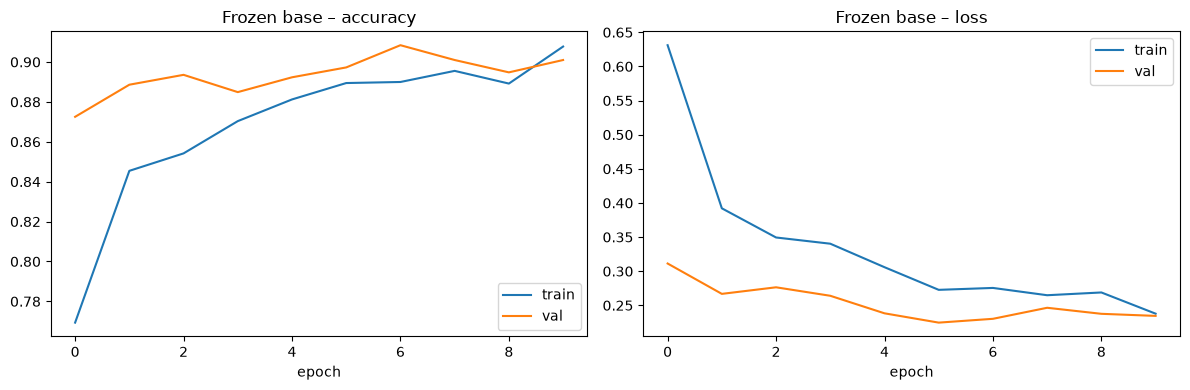

In [12]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, m in zip(ax, ["accuracy", "loss"]):
        a.plot(h.history[m], label="train"); a.plot(h.history[f"val_{m}"], label="val")
        a.set_title(f"{title} – {m}"); a.set_xlabel("epoch"); a.legend()
    plt.tight_layout(); plt.show()

def evaluate(model, ds):
    loss, acc = model.evaluate(ds, verbose=0)
    return loss, acc

model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist_frozen = model.fit(
    train_ds, validation_data=val_ds, epochs=10,
    callbacks=[keras.callbacks.ModelCheckpoint("frozen_best.weights.h5", monitor="val_accuracy", save_best_only=True, save_weights_only=True)])
plot_history(hist_frozen, "Frozen base")

In [13]:
model.load_weights("frozen_best.weights.h5") # restore best frozen checkpoint
frozen_val_loss, frozen_val_acc = evaluate(model, val_ds)
frozen_test_loss, frozen_test_acc = evaluate(model, test_ds)
print(f"Best frozen-base  val acc: {frozen_val_acc:.4f} | val loss: {frozen_val_loss:.4f} | test acc: {frozen_test_acc:.4f}")

Best frozen-base  val acc: 0.9084 | val loss: 0.2303 | test acc: 0.9085


**Curve interpretation:** Look like After 17 - 18 epochs train keep going well but Validation line shows that it start effecting.

# Part 3 – Fine-Tuning

### Unfreezing strategy
* **Layers unfrozen:** the top `N_UNFREEZE = 30` layers of EfficientNetB0 (the last blocks). Early layers learn generic edges/textures that transfer well; later layers are more task-specific, so those benefit most from adaptation.
* **BatchNorm layers stay frozen.** Unfreezing BN with a small batch/learning rate can corrupt the running statistics and destabilise training.
* **Learning rate 1e-5** (100× smaller than the 1e-3 used for the head). Pretrained weights are already good; large updates would destroy that knowledge ("catastrophic forgetting").
* **Schedule:** `ReduceLROnPlateau(factor=0.5, patience=2)` halves the LR when val loss stalls; the LR is logged each epoch and plotted below.
* Training **continues from the frozen-base checkpoint** (already loaded above); weights are not re-initialised.

In [14]:
N_UNFREEZE, FT_LR = 30, 1e-5

class LRLogger(keras.callbacks.Callback):
    # Records the LR used in each epoch into History (placed before ReduceLROnPlateau)
    def on_epoch_end(self, epoch, logs=None):
        logs["lr"] = float(keras.ops.convert_to_numpy(self.model.optimizer.learning_rate))

def unfreeze_top(base, n):
    base.trainable = True
    for layer in base.layers[:-n]:
        layer.trainable = False
    for layer in base.layers[-n:]:
        layer.trainable = not isinstance(layer, layers.BatchNormalization)

before = param_counts(model)
unfreeze_top(base, N_UNFREEZE)
after = param_counts(model)
print("Trainable params  before:", before["trainable"], "| after:", after["trainable"])

model.compile(optimizer=keras.optimizers.Adam(FT_LR), loss="sparse_categorical_crossentropy", metrics=["accuracy"])

Trainable params  before: 329478 | after: 1812838


### Fine-tuning run
Up to 10 epochs with early stopping (patience 3, restoring the best weights).

Epoch 1/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 54s 458ms/step - accuracy: 0.9229 - loss: 0.2094 - val_accuracy: 0.9059 - val_loss: 0.2233 - lr: 1.0000e-05 - learning_rate: 1.0000e-05
Epoch 2/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 52s 444ms/step - accuracy: 0.9160 - loss: 0.2144 - val_accuracy: 0.9047 - val_loss: 0.2241 - lr: 1.0000e-05 - learning_rate: 1.0000e-05
Epoch 3/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 54s 457ms/step - accuracy: 0.9138 - loss: 0.2223 - val_accuracy: 0.9097 - val_loss: 0.2223 - lr: 1.0000e-05 - learning_rate: 1.0000e-05
Epoch 4/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 53s 449ms/step - accuracy: 0.9199 - loss: 0.2113 - val_accuracy: 0.9072 - val_loss: 0.2226 - lr: 1.0000e-05 - learning_rate: 1.0000e-05
Epoch 5/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 54s 459ms/step - accuracy: 0.9178 - loss: 0.2134 - val_accuracy: 0.9134 - val_loss: 0.2214 - lr: 1.0000e-05 - learning_rate: 1.0000e-05
Epoch 6/15
118/118 ━━━━━━━━━━━━━━━━━━━━ 53s 452ms/step - accuracy: 0.9210 - loss: 0.2046 - val_accuracy: 0.9146 - val_lo

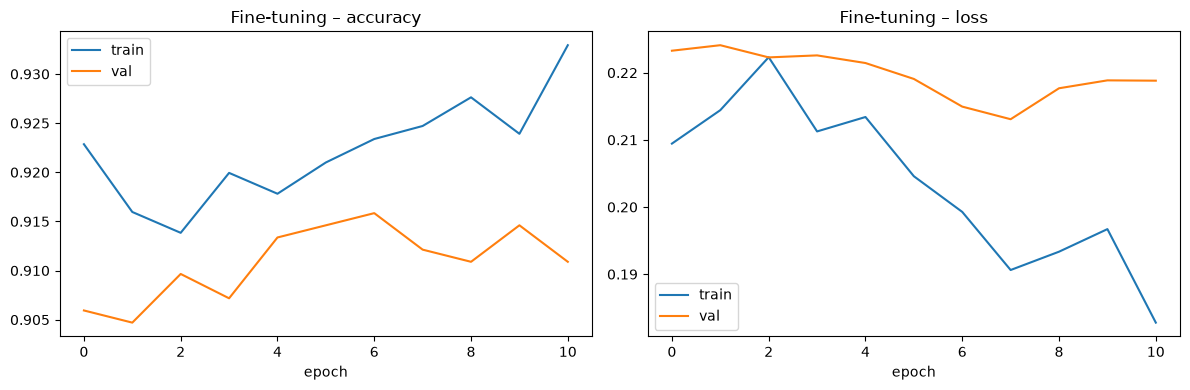

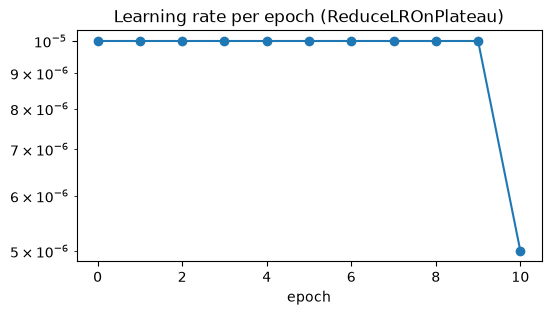

In [17]:
hist_ft = model.fit(
    train_ds, validation_data=val_ds, epochs=15,
    callbacks=[LRLogger(),
               keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-7),
               keras.callbacks.ModelCheckpoint("finetuned_best.weights.h5", monitor="val_accuracy", save_best_only=True, save_weights_only=True),
               keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
plot_history(hist_ft, "Fine-tuning")

plt.figure(figsize=(6, 3)); plt.plot(hist_ft.history["lr"], marker="o")
plt.yscale("log"); plt.title("Learning rate per epoch (ReduceLROnPlateau)"); plt.xlabel("epoch"); plt.show()

### 
Before / after comparison

In [18]:
model.load_weights("finetuned_best.weights.h5")

ft_val_loss, ft_val_acc = evaluate(model, val_ds)
ft_test_loss, ft_test_acc = evaluate(model, test_ds)

comparison = pd.DataFrame({
    "Metric": ["Validation Accuracy", "Validation Loss", "Test Accuracy", "Trainable Params"],
    "Frozen Base": [f"{frozen_val_acc:.4f}", f"{frozen_val_loss:.4f}", f"{frozen_test_acc:.4f}", f"{frozen_params['trainable']:,}"],
    "After Fine-Tuning": [f"{ft_val_acc:.4f}", f"{ft_val_loss:.4f}", f"{ft_test_acc:.4f}", f"{param_counts(model)['trainable']:,}"],
})
comparison

,Metric,Frozen Base,After Fine-Tuning
0,Validation Accuracy,0.9084,0.9158
1,Validation Loss,0.2303,0.2149
2,Test Accuracy,0.9085,0.9073
3,Trainable Params,"329,478","1,812,838"


**Discussion:** After and Before can clearly tell the these both are performing near to each other. But Model After Fine Tuning is Performing a little better then the Frozen Base.

# Evaluation & Analysis
Predictions on the **test set** with the fine-tuned model. Because the test dataset is unshuffled, predictions line up with `test_raw.file_paths`.

In [19]:
y_true = np.concatenate([y.numpy() for _, y in test_raw])
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)

report = classification_report(y_true, y_pred, target_names=class_names, output_dict=True)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

report_df = pd.DataFrame(report).T.loc[class_names]
hardest = report_df["f1-score"].nsmallest(2)

print("Two hardest classes (lowest F1):"); print(hardest)

                precision    recall  f1-score   support

      accident      0.924     0.952     0.937       165
 cctv_accident      0.806     0.714     0.758        70
   cctv_normal      0.739     0.861     0.795        79
 dense_traffic      0.912     0.939     0.925       165
          fire      0.976     0.982     0.979       165
sparse_traffic      0.953     0.861     0.904       165

      accuracy                          0.907       809
     macro avg      0.885     0.885     0.883       809
  weighted avg      0.910     0.907     0.907       809

Two hardest classes (lowest F1):
cctv_accident    0.757576
cctv_normal      0.795322
Name: f1-score, dtype: float64


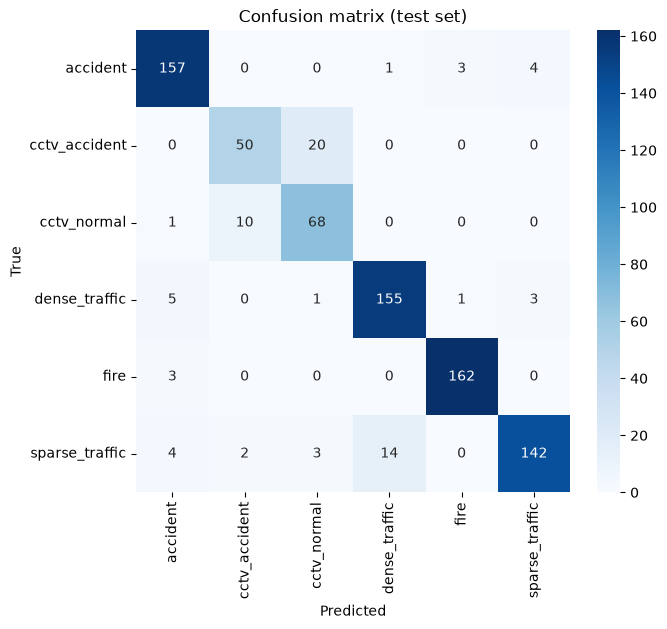

Most common misclassification: true 'cctv_accident' -> predicted 'cctv_normal' (20 images)


In [20]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test set)"); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)

print(f"Most common misclassification: true '{class_names[i]}' -> predicted '{class_names[j]}' ({off[i, j]} images)")

### Error analysis
A grid of misclassified test images (true vs predicted), plus a count of the most frequent (true → predicted) pairs to check whether errors are systematic.

75 misclassified out of 809 test images
                 (true, predicted)  count
0     (cctv_accident, cctv_normal)     20
1  (sparse_traffic, dense_traffic)     14
2     (cctv_normal, cctv_accident)     10
3        (dense_traffic, accident)      5
4       (accident, sparse_traffic)      4
5       (sparse_traffic, accident)      4
6                 (accident, fire)      3
7  (dense_traffic, sparse_traffic)      3


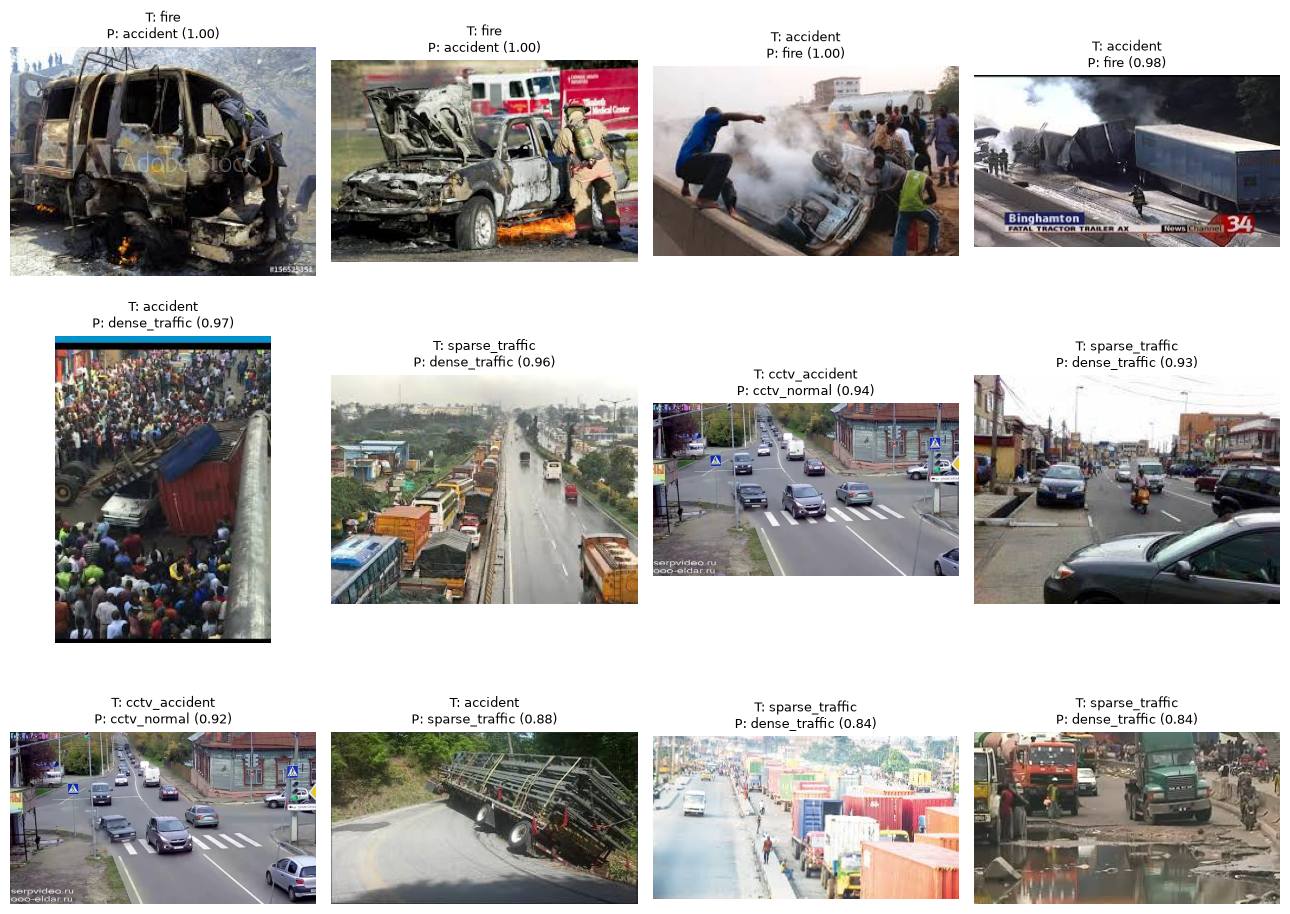

In [21]:
wrong = np.where(y_pred != y_true)[0]
print(f"{len(wrong)} misclassified out of {len(y_true)} test images")

pairs = collections.Counter((class_names[y_true[k]], class_names[y_pred[k]]) for k in wrong)
print(pd.DataFrame(pairs.most_common(8), columns=["(true, predicted)", "count"]))

picked = wrong[np.argsort(-y_prob[wrong].max(axis=1))][:12] # 12 most confident mistakes
paths = [test_raw.file_paths[k] for k in picked]
titles = [f"T: {class_names[y_true[k]]}\nP: {class_names[y_pred[k]]} ({y_prob[k].max():.2f})" for k in picked]
show_grid(paths, titles, 3, 4, figsize=(13, 10))

# Application: Accident AI Alert System for CCTV
The fine-tuned classifier becomes the core of a video alerting pipeline:

1. Every Nth video frame is classified. **P(alert)** = probability of `accident` + `cctv_accident` + `fire`. (`dense_traffic` is deliberately *not* an alert.)
2. P(alert) is **smoothed** over time and must stay above `ALERT_THRESHOLD` for several analysed frames in a row, so one noisy frame cannot trigger an alert.
3. After an alert there is a **cooldown**, so one accident does not send dozens of messages.

First, how good is the alert decision on the untouched test set? The **CCTV-only** report is the one that matters for your cameras.

In [22]:
MODEL_OUT = Path("incident_model.keras")
model.save(MODEL_OUT)

ALERT_CLASSES = ["accident", "cctv_accident", "fire"]
ALERT_IDX = [class_names.index(c) for c in ALERT_CLASSES]
CCTV_ACC, CCTV_OK = class_names.index("cctv_accident"), class_names.index("cctv_normal")
ALERT_THRESHOLD = 0.60
ALERT_DIR = Path("alerts"); ALERT_DIR.mkdir(exist_ok=True)

p_alert_test = y_prob[:, ALERT_IDX].sum(axis=1)
print("ALL test images: alert (accident or fire) vs no alert")
print(classification_report(np.isin(y_true, ALERT_IDX), p_alert_test >= ALERT_THRESHOLD, target_names=["no alert", "alert"], digits=3))

cctv_mask = np.isin(y_true, [CCTV_ACC, CCTV_OK])
print("CCTV frames only: accident vs normal")
print(classification_report(y_true[cctv_mask] == CCTV_ACC, p_alert_test[cctv_mask] >= ALERT_THRESHOLD, target_names=["cctv_normal", "cctv_accident"], digits=3))

ALL test images: alert (accident or fire) vs no alert
              precision    recall  f1-score   support

    no alert      0.919     0.971     0.944       409
       alert      0.968     0.912     0.940       400

    accuracy                          0.942       809
   macro avg      0.944     0.942     0.942       809
weighted avg      0.943     0.942     0.942       809

CCTV frames only: accident vs normal
               precision    recall  f1-score   support

  cctv_normal      0.728     0.949     0.824        79
cctv_accident      0.913     0.600     0.724        70

     accuracy                          0.785       149
    macro avg      0.821     0.775     0.774       149
 weighted avg      0.815     0.785     0.777       149



### Video alert pipeline
`monitor_video` runs the whole pipeline on a video file (cooldown uses video time, so it also works on files). **Set `VIDEO_PATH` to your own CCTV clip.**
If it is `None`, a short demo clip is built from unseen test frames (normal frames first, then accident frames) just to show the pipeline working end to end.
For a live camera pass a stream URL / camera index to `cv2.VideoCapture` instead.

In [23]:
def predict_frame(frame_bgr):
    rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    x = cv2.resize(rgb, IMG_SIZE[::-1]).astype("float32")[None]
    return keras.ops.convert_to_numpy(model(x, training=False))[0]

class TriggerLogic:
    # Smooths P(alert), requires several consecutive high frames, then enforces a cooldown
    def __init__(self, threshold, min_consecutive, cooldown_s, ema=0.5):
        self.threshold, self.min_consecutive, self.cooldown_s, self.ema = threshold, min_consecutive, cooldown_s, ema
        self.smooth, self.streak, self.last_alert = None, 0, -1e9

    def update(self, p, t):
        self.smooth = p if self.smooth is None else self.ema * self.smooth + (1 - self.ema) * p
        self.streak = self.streak + 1 if self.smooth >= self.threshold else 0
        fire = self.streak >= self.min_consecutive and t - self.last_alert >= self.cooldown_s
        if fire:
            self.last_alert, self.streak = t, 0
        return self.smooth, fire

def monitor_video(video_path, every_n=5, threshold=ALERT_THRESHOLD, min_consecutive=3, cooldown_s=30, out_path=None, location="Camera 1"):
    cap = cv2.VideoCapture(str(video_path))
    fps = cap.get(cv2.CAP_PROP_FPS) or 25
    logic, events, writer = TriggerLogic(threshold, min_consecutive, cooldown_s), [], None
    n, label, smooth, last_fire_t = 0, "-", 0.0, -1e9
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        n += 1
        t = n / fps
        if n % every_n == 0:
            probs = predict_frame(frame)
            smooth, fire = logic.update(float(probs[ALERT_IDX].sum()), t)
            label = class_names[int(np.argmax(probs))]
            if fire:
                last_fire_t = t
                snap = ALERT_DIR / f"alert_{len(events) + 1:03d}_{t:06.1f}s.jpg"
                cv2.imwrite(str(snap), frame)
                events.append({"timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"), "video_time": round(t, 1),
                               "location": location, "label": class_names[ALERT_IDX[int(np.argmax(probs[ALERT_IDX]))]],
                               "confidence": round(smooth, 3), "snapshot": str(snap)})
        if out_path:
            alerting = t - last_fire_t < 3
            color = (0, 0, 255) if alerting else (0, 200, 0)
            vis = frame.copy()
            cv2.rectangle(vis, (0, 0), (vis.shape[1] - 1, vis.shape[0] - 1), color, 6 if alerting else 2)
            cv2.putText(vis, f"{label}  P(alert)={smooth:.2f}", (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)
            if writer is None:
                writer = cv2.VideoWriter(str(out_path), cv2.VideoWriter_fourcc(*"mp4v"), fps, (vis.shape[1], vis.shape[0]))
            writer.write(vis)
    cap.release()
    if writer is not None:
        writer.release()
    return events


AI CCTV ACCIDENT DETECTION STARTED
Video: testing_footages\v_1.mp4
Resolution: 720 x 1280
Video FPS: 30.00
Inference interval: Every 3 frames

KEYBOARD CONTROLS
Q / ESC : Stop monitoring
SPACE   : Pause / Resume

!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!
ACCIDENT DETECTED!
Class: cctv_accident
Confidence: 64.40%
Video time: 7.50s
Snapshot: alerts\alert_001_0007.5s.jpg
!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

CCTV MONITORING COMPLETED
Total frames processed: 513
Total accident alerts: 1
Total duration: 17.10s


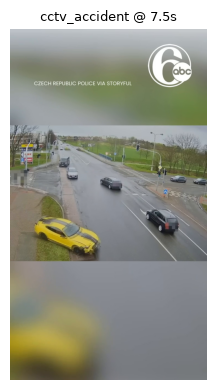

In [32]:

VIDEO_PATH = "./testing_footages/v_1.mp4"
CAMERA_LOCATION = "Camera 1"
EVERY_N = 3

MIN_CONSECUTIVE = 3
COOLDOWN_SECONDS = 30

PLAYBACK_SPEED = 1.0

WINDOW_NAME = "AI CCTV - Accident Detection"

VIDEO_PATH = Path(VIDEO_PATH)

if not VIDEO_PATH.exists():
    raise FileNotFoundError(
        f"CCTV video not found: {VIDEO_PATH.resolve()}"
    )

if EVERY_N < 1:
    raise ValueError("EVERY_N must be at least 1.")

if PLAYBACK_SPEED <= 0:
    raise ValueError("PLAYBACK_SPEED must be greater than zero.")

alert_indices = np.asarray(ALERT_IDX, dtype=int)

if len(alert_indices) == 0:
    raise ValueError("ALERT_IDX cannot be empty.")

if np.any(alert_indices < 0) or np.any(
    alert_indices >= len(class_names)
):
    raise ValueError("ALERT_IDX contains invalid class indices.")

def predict_frame(frame_bgr):
    rgb = cv2.cvtColor(frame_bgr,cv2.COLOR_BGR2RGB)
    resized = cv2.resize(rgb,IMG_SIZE[::-1])
    x = resized.astype("float32")[None]
    predictions = keras.ops.convert_to_numpy(model(x, training=False))[0]
    return predictions

class TriggerLogic:

    def __init__(self,threshold,min_consecutive,cooldown_s,ema=0.5):
        self.threshold = threshold
        self.min_consecutive = min_consecutive
        self.cooldown_s = cooldown_s
        self.ema = ema
        self.smooth = None
        self.streak = 0
        self.last_alert = -1e9

    def update(self, probability, timestamp):
        if self.smooth is None:
            self.smooth = probability

        else:
            self.smooth = (self.ema * self.smooth + (1 - self.ema) * probability)

        if self.smooth >= self.threshold:
            self.streak += 1

        else:
            self.streak = 0

        fire = (self.streak >= self.min_consecutive and timestamp - self.last_alert >= self.cooldown_s )

        if fire:
            self.last_alert = timestamp
            self.streak = 0

        return self.smooth, fire

def monitor_video(
    video_path,
    every_n=EVERY_N,
    threshold=ALERT_THRESHOLD,
    min_consecutive=MIN_CONSECUTIVE, cooldown_s=COOLDOWN_SECONDS, location=CAMERA_LOCATION, playback_speed=PLAYBACK_SPEED):

    cap = cv2.VideoCapture(str(video_path))

    if not cap.isOpened():
        raise RuntimeError(f"Unable to open video: {video_path}")

    fps = cap.get(cv2.CAP_PROP_FPS)

    if not np.isfinite(fps) or fps <= 0:
        fps = 25.0

    width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    frame_delay = max(1, int(1000 / (fps * playback_speed)) )

    logic = TriggerLogic( threshold=threshold, min_consecutive=min_consecutive, cooldown_s=cooldown_s )

    events = []

    writer = None
    frame_count = 0
    label = "MONITORING"
    smooth = 0.0
    last_fire_t = -1e9
    inference_time = 0.0
    inference_fps = 0.0

    cv2.namedWindow(WINDOW_NAME, cv2.WINDOW_NORMAL)
    cv2.resizeWindow(WINDOW_NAME, min(width, 1280), min(height, 720))

    print("\n" + "=" * 60)
    print("AI CCTV ACCIDENT DETECTION STARTED")
    print("=" * 60)

    print(f"Video: {video_path}")
    print(f"Resolution: {width} x {height}")
    print(f"Video FPS: {fps:.2f}")
    print(f"Inference interval: Every {every_n} frames")

    print("\nKEYBOARD CONTROLS")
    print("Q / ESC : Stop monitoring")
    print("SPACE   : Pause / Resume")
    print("=" * 60)

    paused = False

    try:
        while cap.isOpened():
            if paused:
                key = cv2.waitKey(30) & 0xFF
                if key == ord("q") or key == 27:
                    break

                if key == ord(" "): paused = False
                continue

            ret, frame = cap.read()

            if not ret: break

            frame_count += 1
            video_time = frame_count / fps


            if frame_count % every_n == 0:
                start_time = time.perf_counter()
                predictions = predict_frame(frame)
                inference_time = (time.perf_counter() - start_time)
                
                inference_fps = (
                    1.0 / inference_time
                    if inference_time > 0
                    else 0.0
                )

                accident_probability = float(np.sum(predictions[alert_indices]))
                smooth, fire = logic.update(accident_probability,video_time)
                predicted_idx = int(np.argmax(predictions))
                label = class_names[predicted_idx]

                if fire:
                    last_fire_t = video_time
                    accident_idx = int(alert_indices[np.argmax(predictions[alert_indices])])
                    accident_label = class_names[ accident_idx ]
                    snapshot_path = ( ALERT_DIR / f"alert_{len(events)+1:03d}_" f"{video_time:06.1f}s.jpg" )
                    cv2.imwrite( str(snapshot_path), frame )

                    event = {
                        "timestamp": datetime.now().strftime( "%Y-%m-%d %H:%M:%S" ),
                        "video_time": round( video_time, 1 ),
                        "location": location,
                        "label": accident_label,
                        "confidence": round( smooth, 3 ),
                        "snapshot": str( snapshot_path )
                    }

                    events.append(event)

                    print("\n" + "!" * 55)
                    print("ACCIDENT DETECTED!")
                    print(f"Class: {accident_label}")
                    print(f"Confidence: {smooth:.2%}")
                    print(f"Video time: {video_time:.2f}s")
                    print(f"Snapshot: {snapshot_path}")
                    print("!" * 55)

            vis = frame.copy()
            alerting = ( video_time - last_fire_t < 3 )

            if alerting:
                status = "ACCIDENT DETECTED!"
                color = (0, 0, 255)

            elif smooth >= threshold:
                status = "POTENTIAL ACCIDENT"
                color = (0, 165, 255)

            else:
                status = "NORMAL MONITORING"
                color = (0, 200, 0)

            # Information panel
            cv2.rectangle( vis, (0, 0), (width, 165), (25, 25, 25), -1 )
            cv2.putText( vis, status, (20, 35), cv2.FONT_HERSHEY_SIMPLEX, 0.85, color, 2 )
            cv2.putText( vis, f"Prediction: {label}", (20, 70), cv2.FONT_HERSHEY_SIMPLEX, 0.65, (255, 255, 255), 2 )
            cv2.putText( vis, f"P(Accident): {smooth:.2%}", (20, 105), cv2.FONT_HERSHEY_SIMPLEX, 0.65, color, 2 )
            cv2.putText(
                vis,
                (
                    f"Time: {video_time:.1f}s | "
                    f"Inference: {inference_time*1000:.1f}ms | "
                    f"FPS: {inference_fps:.1f}"
                ),
                (20, 140), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 255), 1 
                )

            # Border
            cv2.rectangle( vis, (0, 0), (width - 1, height - 1), color, 4 )
            cv2.imshow( WINDOW_NAME, vis )

            key = cv2.waitKey(frame_delay) & 0xFF
            if key == ord("q") or key == 27:
                print("\nMonitoring stopped.")
                break

            elif key == ord(" "):
                paused = True

    finally:
        cap.release()
        if writer is not None:
            writer.release()

        cv2.destroyAllWindows()

    print("\n" + "=" * 60)
    print("CCTV MONITORING COMPLETED")
    print("=" * 60)
    print(f"Total frames processed: {frame_count}")
    print(f"Total accident alerts: {len(events)}")
    print(f"Total duration: {frame_count / fps:.2f}s")
    
    print("=" * 60)
    return events

events = monitor_video(
    video_path=VIDEO_PATH,
    every_n=EVERY_N,
    threshold=ALERT_THRESHOLD,
    min_consecutive=MIN_CONSECUTIVE,
    cooldown_s=COOLDOWN_SECONDS,
    location=CAMERA_LOCATION,
    playback_speed=PLAYBACK_SPEED
)

if events:
    shown = events[:4]
    show_grid(
        [event["snapshot"] for event in shown],
        [ f"{event['label']} @ {event['video_time']}s" for event in shown ], 1, len(shown), figsize=(4 * len(shown), 4) )

else:
    print("\nNo accident alerts were triggered.")


**Limitations of this alert system:** _(edit if you like)_ it classifies single frames (no motion), and it was trained on a merged dataset whose CCTV part is small and may not look like your cameras
(angle, resolution, night, weather). Expect false alarms from heavy traffic, shadows or camera shake. Tune `ALERT_THRESHOLD`, `min_consecutive` and `every_n` on your own footage,
fine-tune on frames from your cameras if possible, and always have a person confirm alerts. It is a prototype, not a certified safety system.

# Reflection

### Dataset choice
**Your answer:** Try to find some database according to project plan on which i was thinking to work but many issues where there and many of dataset were not according to our desired criteria

### Architecture choice
**Your answer:** Use EfficientNET because of Lightweight and a 4M params model. That can work on my end and willl work on other Lower specification as well

### Fine-tuning decisions
**Your answer:** I can see both models are near to each other but Fine Tuned one is working fine.

### What would you do next
**Your answer:** Try to improve this to make an End to end proper model to work in real world.